In [1]:
import numpy as np
import cobra
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pickle
import sys
sys.path.append('../../')
from helper_function import *

plt.rcParams['font.family'] = 'Arial'

In [2]:
with open("../../FBAsolution/Nutrient_specialization_analysis_423.pkl", "rb") as f:
    data = pickle.load(f)
    origin_TL = data['origin_TL']
    dropout_TL = data['dropout_TL']
    selected = data['selected']
    del data

In [3]:
def mse(b, a):
    # simple mean squared error for numpy arrays
    #return np.mean((a - b) ** 2)
    delta = np.mean(abs(np.divide((a - b), b, out=np.zeros_like(b, dtype=float), where=(b > 1e-3))))
    return np.sum(abs(np.array(b - a)))
    #return delta

def cosine_similarity(a, b):
    # cosine similarity for numpy arrays
    dot_product = np.dot(a, b)
    norm_a = np.linalg.norm(a)
    norm_b = np.linalg.norm(b)
    if norm_a == 0 or norm_b == 0:
        return 0.0
    return dot_product / (norm_a * norm_b)

total_data = []

for i, tl in enumerate(origin_TL):
    if tl:
        origin_E, origin_gr = tl[3], tl[2]

        for dropout_tl in dropout_TL[i]:
            if dropout_tl:
                dropout_E, dropout_gr = dropout_tl[6], dropout_tl[2]

                dropout_nutrient = 'Specialized' if dropout_tl[4] in selected else 'Multifuncional'

                delta_E = mse(origin_E, dropout_E)
                delta_gr = (origin_gr - dropout_gr) / origin_gr

                total_data.append((delta_E, delta_gr, dropout_nutrient))

In [4]:
#  species_idx  dropout_idx  nutrient_id   DeltaE  DeltaGR
#           93            2         True 0.023999 0.977637
#          202            5         True 0.004907 0.938691
#          145           16         True 0.000372 0.919437
#          131            2         True 0.002167 0.789384
#          138           13         True 0.000844 0.561483
#          131            3         True 0.000805 0.503026
#           77            3         True 0.005022 0.489473
#           81            2         True 0.000330 0.322895
#           37           22         True 0.000186 0.291209
#            9            5         True 0.002133 0.273297
#            9            8         True 0.001055 0.266863
#           89           21         True 0.000418 0.230950
#           39           11         True 0.000285 0.227820
#           54            9         True 0.005641 0.222958
#           79            5         True 0.001148 0.180500

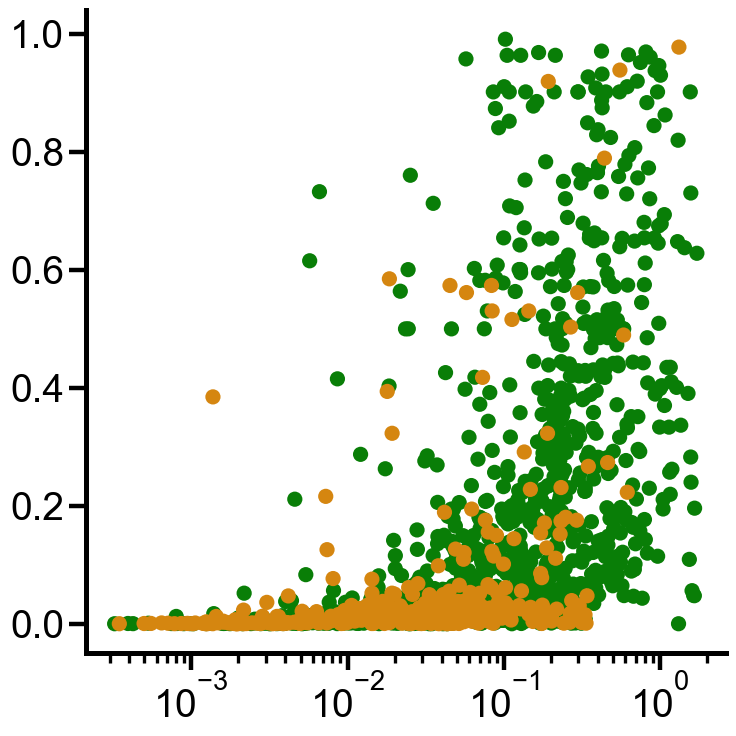

In [5]:
multifunctional_color = "#097E07"  # dark green
specialized_color     = "#D58610"  # dark goldenrod (deep yellow)

set_panel_style(scale=4)

arr = np.array(total_data, dtype=object)
x = arr[:, 0].astype(float)
y = arr[:, 1].astype(float)
TF_flag = np.array([d[2] == "Specialized" for d in total_data], dtype=bool)

plt.figure(figsize=(8, 8))

# Multifunctional
plt.scatter(
    x[~TF_flag], y[~TF_flag],
    s=120, alpha=1,
    color=multifunctional_color,
    edgecolors="none"
)

# Specialized
plt.scatter(
    x[TF_flag], y[TF_flag],
    s=120, alpha=1,
    color=specialized_color,
    edgecolors="none"
)

plt.xscale("log")


ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

#ax.set_xlim(1e-3, 10)

plt.tight_layout()
#plt.savefig("Figure3E.pdf", format="pdf", pad_inches=0.5)
plt.show()